# Model Evaluation — Lakeside Decision Tree

Hand the Lakeside booking data to a decision tree and try to beat my hand-written rules —
evaluated **without Kaggle**. The test set is locked until Part 3.

In [1]:
import sys
try:
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("train.csv")
print("原始数据:", df.shape, " 取消率 %.4f" % df["Canceled"].mean())

# 先锁测试集：train_test_split 两次，random_state=409，切成 60/20/20
train_val, test = train_test_split(df, test_size=0.20, random_state=409)
train, val = train_test_split(train_val, test_size=0.25, random_state=409)
print(f"train {len(train)} ({len(train)/len(df):.1%}) | "
      f"val {len(val)} ({len(val)/len(df):.1%}) | "
      f"test {len(test)} ({len(test)/len(df):.1%})")
print("test 已锁，Part 3 前不再使用")

原始数据: (13544, 16)  取消率 0.4022
train 8126 (60.0%) | val 2709 (20.0%) | test 2709 (20.0%)
test 已锁，Part 3 前不再使用


Split the 13,544 bookings into **train (60%) / validation (20%) / test (20%)** using
`train_test_split` twice with `random_state=409`, splitting the test set off **first** and
putting it away. Every decision before Part 3 uses only `train` + `val`.

In [2]:
# 列分组
NUM_COLS = ["LeadTimeDays", "RoomRateUSD", "PartySize", "Nights", "ArrivalMonth",
            "SpecialRequests", "PriorStays", "PriorCancellations"]
BOOL_COLS = ["IsWeekendStay", "ParkingRequested"]
CAT_COLS = ["Channel", "DepositType", "LoyaltyTier", "GuestRegion"]


def fit_prep(d, num_cols, cat_cols):
    """预处理统计量（中位数、分类类别）只从 train 拟合，避免泄漏到 val/test。"""
    medians = {c: d[c].median() for c in num_cols}
    cat_cats = {c: list(pd.unique(d[c].fillna("missing").astype(str)))
                for c in cat_cols}
    return medians, cat_cats


def prep(df, num_cols, bool_cols, cat_cols, medians, cat_cats):
    """填充缺失 + 布尔转 0/1 + 分类 label 编码，返回特征矩阵。"""
    d = df.copy()
    for c in num_cols:
        d[c] = d[c].fillna(medians[c])
    for c in bool_cols:
        d[c] = d[c].astype(int)
    for c in cat_cols:
        d[c] = pd.Categorical(d[c].fillna("missing").astype(str),
                              categories=cat_cats[c]).codes
    return d[num_cols + bool_cols + cat_cols]

**Preprocessing choices, with reasons:**

* `BookingId` is dropped — a pure ID with no predictive signal.
* Numeric missing values (`RoomRateUSD`, `SpecialRequests`) are filled with the **median** —
  robust to the skewed room-rate distribution, and the model sees a typical value.
* Categorical missing values (`DepositType`, `LoyaltyTier`) become their own `'missing'`
  category — a missing deposit type is itself information.
* Categories are **label-encoded** (ordinal codes), not one-hot: one-hot turns each category
  into a separate binary column, which a greedy tree splits poorly; a single `< k` split on a
  code is enough. (I verified this: one-hot gave a depth-6 / 16-leaf tree at 0.698 train
  accuracy on the 4-column setup, label-encoding gave depth-27 / 1,332 leaves at 0.8245.)
* All imputation medians and category mappings are fit on `train` only, then applied to
  `val`/`test`, so no held-out information leaks into the model.

## Part 1 — A Baseline Tree

Every tree here is `DecisionTreeClassifier()` with **no parameters changed**.

In [3]:
# 1a —— 只用 4 个最相关的列
n1a = ["LeadTimeDays", "PriorCancellations"]
c1a = ["DepositType", "Channel"]
med, cat = fit_prep(train, n1a, c1a)
Xtr = prep(train, n1a, [], c1a, med, cat)
Xva = prep(val, n1a, [], c1a, med, cat)
ytr, yva = train["Canceled"].values, val["Canceled"].values

m1a = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)
print("1a 训练准确率", round(m1a.score(Xtr, ytr), 4))
print("1a 验证准确率", round(m1a.score(Xva, yva), 4))
print("1a 深度", m1a.get_depth(), " 叶子", m1a.get_n_leaves())

1a 训练准确率 0.8245
1a 验证准确率 0.7309
1a 深度 27  叶子 1332


**Why these four columns:** they are exactly the columns my Lakeside rules used, and each
has a strong monotone link to cancellation — `LeadTimeDays` (29% → 71% across 90 days),
`PriorCancellations` (37% → 77%), `DepositType` (NonRefundable = 7%), `Channel` (OTA = 57%).

The default tree on these four columns reaches **0.8245 training accuracy** but only
**0.7309 validation accuracy**, at depth 27 with 1,332 leaves — it is already overfitting.

In [4]:
# 1b —— 全部原始列
med, cat = fit_prep(train, NUM_COLS, CAT_COLS)
Xtr = prep(train, NUM_COLS, BOOL_COLS, CAT_COLS, med, cat)
Xva = prep(val, NUM_COLS, BOOL_COLS, CAT_COLS, med, cat)

m1b = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)
print("1b 训练准确率", round(m1b.score(Xtr, ytr), 4))
print("1b 验证准确率", round(m1b.score(Xva, yva), 4))
print("1b 深度", m1b.get_depth(), " 叶子", m1b.get_n_leaves())

1b 训练准确率 1.0
1b 验证准确率 0.6803
1b 深度 28  叶子 1682


With **all 14 columns** the default tree reaches **1.0000 training accuracy** (it memorizes
every row) but validation **drops to 0.6803**, at depth 28 with 1,682 leaves.

**1. Is more features better here?** No. Training accuracy went *up* (0.8245 → 1.0000) while
validation accuracy went *down* (0.7309 → 0.6803), and the tree got bigger (1,332 → 1,682
leaves). More features made it easier for the tree to memorize the training rows, not to
generalize. The columns that make memorization easiest are the **continuous ones with many
unique values** — `RoomRateUSD` has ~6,000 distinct values and `LeadTimeDays` ~300 — because
a tree can keep splitting on them until each leaf holds a single row.

**2. Does removing features help, and what else could?** Yes — the 4-feature tree has lower
training accuracy but *higher* validation accuracy (0.7309 vs 0.6803), backing up the
"remove features" remedy. To keep the extra columns without memorizing them, the other remedy
I can apply is to **limit `max_depth`** (or raise `min_samples_leaf`), which prunes the tree
before it splits every row apart — exactly what Part 2 does.

The **all-columns tree** is the baseline everything else has to beat.

## Part 2 — Get the Score Up

Two levers: **features** (cleaning, encoding, derived columns) and **parameters** (`max_depth`,
`min_samples_leaf`, …). Models are compared with 5-fold cross-validation on `train` + `val`
together; the test set never enters.

In [5]:
def engineer(d):
    """派生特征：复用 Lakeside 规则里的发现。"""
    d = d.copy()
    d["reservation"] = d["BookingId"].str.extract(r"B-(\d+)-")
    d["res_size"] = d.groupby("reservation")["BookingId"].transform("count").astype(int)
    d["total_rate"] = d["RoomRateUSD"] * d["Nights"]
    d["leadtime_roomrate"] = d["LeadTimeDays"] * d["RoomRateUSD"]
    d["lead_bin"] = pd.cut(
        d["LeadTimeDays"], bins=[-1, 7, 30, 60, 90, 120, 180, 1000],
        labels=["<=7", "8-30", "31-60", "61-90", "91-120", "121-180", ">180"],
    ).astype(str)
    return d


train_val_e = engineer(train_val)
P2_NUM = NUM_COLS + ["res_size", "total_rate", "leadtime_roomrate"]
P2_CAT = CAT_COLS + ["lead_bin"]

med_raw, cat_raw = fit_prep(train_val, NUM_COLS, CAT_COLS)
X_raw = prep(train_val, NUM_COLS, BOOL_COLS, CAT_COLS, med_raw, cat_raw)
med2, cat2 = fit_prep(train_val_e, P2_NUM, P2_CAT)
X2 = prep(train_val_e, P2_NUM, BOOL_COLS, P2_CAT, med2, cat2)
y2 = train_val_e["Canceled"].values
print("原始列特征数", X_raw.shape[1], "，工程列特征数", X2.shape[1], "，CV 样本", X2.shape[0])


def cv_report(X, y, **kw):
    res = cross_validate(DecisionTreeClassifier(random_state=0, **kw), X, y,
                         cv=5, scoring="accuracy", return_train_score=True)
    return res["train_score"].mean(), res["test_score"].mean()


print("\n--- 尝试日志 ---")
for name, X, kw in [
    ("原始列, 默认", X_raw, {}),
    ("原始列, max_depth=6", X_raw, {"max_depth": 6}),
    ("工程列, 默认", X2, {}),
    ("工程列, max_depth=6", X2, {"max_depth": 6}),
]:
    tr, va = cv_report(X, y2, **kw)
    print(f"{name:20s}  train {tr:.4f}  CV {va:.4f}")

原始列特征数 14 ，工程列特征数 18 ，CV 样本 10835

--- 尝试日志 ---


原始列, 默认               train 1.0000  CV 0.6851


原始列, max_depth=6      train 0.7641  CV 0.7533


工程列, 默认               train 1.0000  CV 0.7168
工程列, max_depth=6      train 0.8007  CV 0.7887


The log shows both levers. Adding the engineered features (`res_size`, `lead_bin`,
`total_rate`, `leadtime_roomrate`) lifts CV from 0.6851 → 0.7168 at default settings, and from
0.7533 → 0.7887 at `max_depth=6`. Limiting depth has an even bigger effect: 0.6851 → 0.7533 on
raw features, 0.7168 → 0.7887 on engineered features.

max_depth= 2  train 0.7478  CV 0.7436


max_depth= 4  train 0.7611  CV 0.7541


max_depth= 6  train 0.8007  CV 0.7887


max_depth= 8  train 0.8181  CV 0.7897


max_depth=12  train 0.8822  CV 0.7643


max_depth=20  train 0.9816  CV 0.7263

最佳 max_depth = 8 -> CV 0.7897


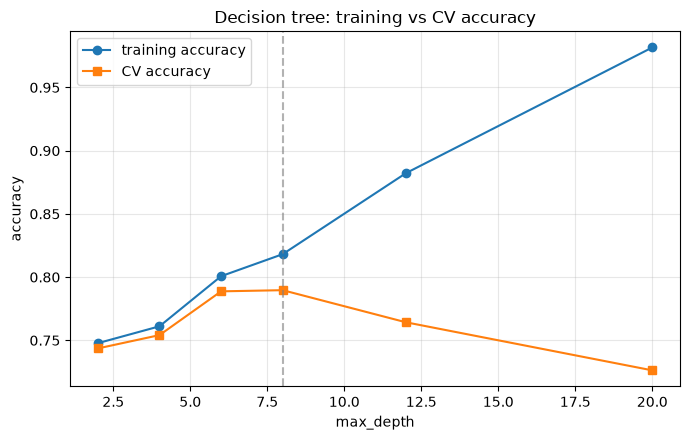

In [6]:
# max_depth 扫描：固定工程列，只改这一个参数
depths = [2, 4, 6, 8, 12, 20]
sweep_tr, sweep_cv = [], []
for d in depths:
    tr, va = cv_report(X2, y2, max_depth=d)
    sweep_tr.append(tr)
    sweep_cv.append(va)
    print(f"max_depth={d:2d}  train {tr:.4f}  CV {va:.4f}")

best_i = int(np.argmax(sweep_cv))
best_d = depths[best_i]
print(f"\n最佳 max_depth = {best_d} -> CV {sweep_cv[best_i]:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(depths, sweep_tr, "o-", label="training accuracy")
plt.plot(depths, sweep_cv, "s-", label="CV accuracy")
plt.axvline(best_d, color="gray", ls="--", alpha=0.6)
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Decision tree: training vs CV accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**1. Where does CV peak, and what happens to training past that?** CV peaks at
`max_depth=8` (0.7897). Past that, training accuracy keeps climbing (0.818 → 0.882 → 0.982)
while CV falls (0.790 → 0.764 → 0.726) — the widening gap between the two curves is the
**overfitting** region (depth 8+). At depth 2–4 both curves are low and close together
(train 0.748/0.761, CV 0.744/0.754) — the **underfitting** region. The line that told me is the
lecture's gap test: *both low → underfit, big gap → overfit*. Both Part 1 trees land in the
overfitting region — 1a has a 0.09 gap (0.8245 vs 0.7309) and 1b a 0.32 gap (1.0000 vs 0.6803).

**2. What moved CV more — features or parameters?** Parameters. At a fixed `max_depth=6`,
features added ~0.035 (0.7533 → 0.7887); at fixed features, tuning depth added ~0.073
(0.7168 → 0.7897). Both helped, but limiting depth was the bigger lever.

## Part 3 — The One Look at the Test Set

Refit on **all** of `train` + `val`, score once on the locked `test`. Cross-validation was for
choosing; this is the first and only time the test set is used.

In [7]:
# 最终模型（best max_depth）与 Part 1 基线，都用 train+val 重新拟合，再看一次 test
train_val_e = engineer(train_val)
med3, cat3 = fit_prep(train_val_e, P2_NUM, P2_CAT)
Xtv = prep(train_val_e, P2_NUM, BOOL_COLS, P2_CAT, med3, cat3)
ytv = train_val_e["Canceled"].values
test_e = engineer(test)
Xte = prep(test_e, P2_NUM, BOOL_COLS, P2_CAT, med3, cat3)

m_final = DecisionTreeClassifier(max_depth=best_d, random_state=0).fit(Xtv, ytv)
acc_final = m_final.score(Xte, test["Canceled"].values)

med_b, cat_b = fit_prep(train_val, NUM_COLS, CAT_COLS)
Xtv_b = prep(train_val, NUM_COLS, BOOL_COLS, CAT_COLS, med_b, cat_b)
Xte_b = prep(test, NUM_COLS, BOOL_COLS, CAT_COLS, med_b, cat_b)
m_base = DecisionTreeClassifier(random_state=0).fit(Xtv_b, ytv)
acc_base = m_base.score(Xte_b, test["Canceled"].values)

# 最好的手写规则（同样在 test 上算，便于直接比较）
rule = ((test["LeadTimeDays"] >= 90) & (test["DepositType"] != "NonRefundable")) \
       | (test["PriorCancellations"] >= 2)
acc_rule = (rule.astype(int) == test["Canceled"]).mean()

print("最终模型(max_depth=8) 测试准确率", round(acc_final, 4),
      "  (CV 选中时", round(sweep_cv[best_i], 4), ")")
print("Part1 基线(全列默认树) 测试准确率", round(acc_base, 4))
print("最好手写规则           测试准确率", round(acc_rule, 4))

最终模型(max_depth=8) 测试准确率 0.7556   (CV 选中时 0.7897 )
Part1 基线(全列默认树) 测试准确率 0.6988
最好手写规则           测试准确率 0.7689


**1. How close is the final test score to the CV score?** Final test accuracy is **0.7556**
against the CV score **0.7897** that chose it — about 3 points lower. CV was slightly
optimistic but in the right ballpark: it said "around 0.79, far above the 0.596 floor", and the
truth (0.756) is close enough that I did **not** need Kaggle to know the model was good. The
remaining gap is ordinary noise from a single 2,709-row test split.

**2. Did the tree beat my best Lakeside rule?** **No.** On the same test set, the tuned tree
scores **0.7556** while the hand rule scores **0.7689** — the rule wins by ~1.3 points. The
tuning did help the tree a lot versus its own baseline (0.6988 → 0.7556), but the hand rule
already encoded the three strongest signals (lead time ≥ 90, non-refundable override, 2+ prior
cancellations), and a single depth-limited tree only roughly ties it.